# Khám phá ECG PTB-XL

Notebook đọc dữ liệu trong thư mục ecg-dataset của project. Chạy từ trên xuống khi working directory là gốc repository. Mục tiêu là xem cấu trúc, nhãn và tín hiệu; notebook **không train model**.

Dataset này là PTB-XL v1.0.2: 21.837 bản ghi 10 giây, 12 chuyển đạo, từ 18.885 người. records100 và records500 là **hai phiên bản cùng một bản ghi**, không phải hai tập dữ liệu độc lập. [Tài liệu PhysioNet](https://physionet.org/content/ptb-xl/1.0.2/).

In [1]:
from pathlib import Path
from collections import Counter
import ast
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path.cwd() / "ecg-dataset"
if not (DATA_DIR / "ptbxl_database.csv").is_file():
    raise FileNotFoundError("Hãy chạy notebook từ gốc repository, nơi có ecg-dataset/")
LEADS = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Đang đọc:", DATA_DIR)


Matplotlib is building the font cache; this may take a moment.


Đang đọc: /Users/bach/Downloads/AI Projects/fall-detection-sic-capstone/ecg-dataset


## 1. Metadata: một hàng là một bản ghi

ptbxl_database.csv chứa ID bản ghi, ID người, nhãn, fold và đường dẫn hai phiên bản tín hiệu. scp_statements.csv giải nghĩa mã nhãn. File .hea mô tả cách đọc file sóng .dat.

In [2]:
meta = pd.read_csv(DATA_DIR / "ptbxl_database.csv")
statements = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)
meta["codes"] = meta.scp_codes.map(ast.literal_eval)

print(f"Bản ghi: {len(meta):,}; người bệnh: {meta.patient_id.nunique():,}")
print("Số cột metadata:", len(meta.columns) - 1)
print("Cột:", [c for c in meta.columns if c != "codes"])
print("Tuổi bị thiếu:", int(meta.age.isna().sum()))
print("Mỗi người ở đúng một fold:", meta.groupby("patient_id").strat_fold.nunique().max() == 1)
display(meta.loc[meta.ecg_id.isin([1, 351]),
                 ["ecg_id", "patient_id", "age", "sex", "scp_codes", "strat_fold",
                  "filename_lr", "filename_hr"]])


Bản ghi: 21,837; người bệnh: 18,885
Số cột metadata: 28
Cột: ['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']
Tuổi bị thiếu: 89
Mỗi người ở đúng một fold: True


,ecg_id,patient_id,age,sex,scp_codes,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",3,records100/00000/00001_lr,records500/00000/00001_hr
350,351,5304.0,90.0,1,"{'AFIB': 100.0, 'NST_': 0.0}",4,records100/00000/00351_lr,records500/00000/00351_hr


## 2. Nhãn là nhiều mã trên cùng một bản ghi

scp_codes là dictionary gồm mã và likelihood. Giá trị 0 nghĩa là **không rõ likelihood**, không phải nhãn âm tính. Cùng một ECG có thể có nhiều nhãn. [Quy ước PTB-XL](https://physionet.org/content/ptb-xl/1.0.2/).

In [3]:
code_counts = Counter(code for codes in meta.codes for code in codes)
for code in ["NORM", "AFIB", "PVC", "SR"]:
    row = statements.loc[code]
    print(f"{code:5s}: {code_counts[code]:5d} bản ghi | {row['description']}")
afib_values = meta.codes.map(lambda codes: codes.get("AFIB"))
print("AFIB likelihood (0 = không rõ):", afib_values.value_counts(dropna=True).to_dict())
print("Có đồng thời AFIB và NORM:",
      sum("AFIB" in codes and "NORM" in codes for codes in meta.codes))
print("Ví dụ record 351:", meta.loc[meta.ecg_id == 351, "codes"].iloc[0])


NORM :  9528 bản ghi | normal ECG
AFIB :  1514 bản ghi | atrial fibrillation
PVC  :  1146 bản ghi | ventricular premature complex
SR   : 16782 bản ghi | sinus rhythm
AFIB likelihood (0 = không rõ): {0.0: 1466, 100.0: 48}
Có đồng thời AFIB và NORM: 37
Ví dụ record 351: {'AFIB': 100.0, 'NST_': 0.0}


## 3. Xem phân bố fold, chẩn đoán và mã nhịp

Mỗi thanh là số bản ghi **có mã đó**. Các thanh nhãn có thể chồng lấp vì dữ liệu đa nhãn. Fold PTB-XL được chia theo người; gợi ý từ PhysioNet là 1–8 train, 9 validation, 10 test.

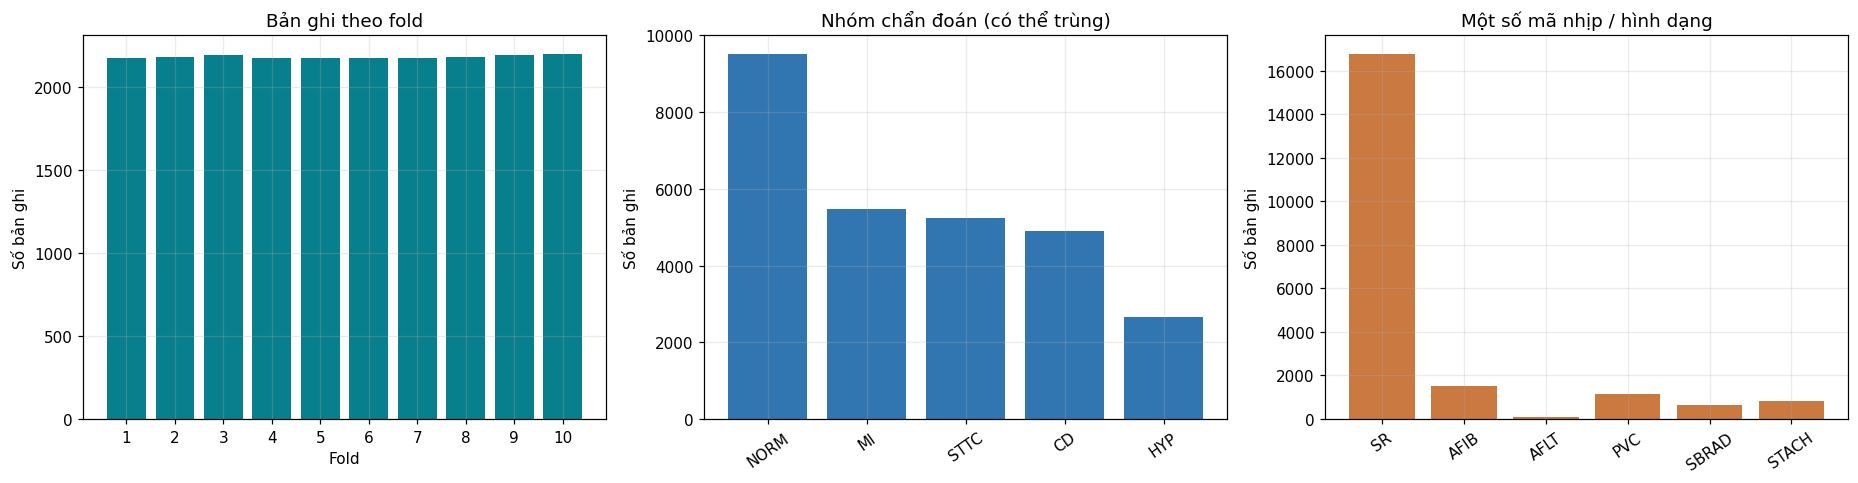

In [4]:
diagnostic_map = statements.loc[statements.diagnostic == 1, "diagnostic_class"].dropna().to_dict()
groups = [set(diagnostic_map[c] for c in codes if c in diagnostic_map)
          for codes in meta.codes]
group_counts = Counter(group for row in groups for group in row)
fold_counts = meta.strat_fold.value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].bar(fold_counts.index, fold_counts.values, color="#087f8c")
axes[0].set(title="Bản ghi theo fold", xlabel="Fold", ylabel="Số bản ghi",
            xticks=range(1, 11))
classes = ["NORM", "MI", "STTC", "CD", "HYP"]
axes[1].bar(classes, [group_counts[c] for c in classes], color="#3276b1")
axes[1].set(title="Nhóm chẩn đoán (có thể trùng)", ylabel="Số bản ghi")
codes = ["SR", "AFIB", "AFLT", "PVC", "SBRAD", "STACH"]
axes[2].bar(codes, [code_counts[c] for c in codes], color="#ca7940")
axes[2].set(title="Một số mã nhịp / hình dạng", ylabel="Số bản ghi")
for ax in axes[1:]:
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()


## 4. Đọc tín hiệu .hea và .dat bằng NumPy

Bản local dùng WFDB format 16: tại mỗi thời điểm có 12 số nguyên 16-bit theo thứ tự lead trong header. Gain 1000/mV nghĩa là mỗi đơn vị số tương ứng 1 µV; hàm trả kết quả bằng mV. Hàm kiểm tra header và kích thước file. Đây là bộ đọc cho đúng format của PTB-XL local, không phải parser WFDB tổng quát.

In [5]:
def load_ptbxl(ecg_id: int, sample_rate: int = 100):
    if sample_rate not in (100, 500):
        raise ValueError("Chọn 100 hoặc 500 Hz")
    row = meta.loc[meta.ecg_id == ecg_id]
    if len(row) != 1:
        raise ValueError(f"Không thấy ecg_id={ecg_id}")
    field = "filename_lr" if sample_rate == 100 else "filename_hr"
    base = DATA_DIR / row.iloc[0][field]
    lines = base.with_suffix(".hea").read_text().splitlines()
    n_leads, fs, n_samples = map(int, lines[0].split()[1:4])
    if (n_leads, fs, n_samples) != (12, sample_rate, sample_rate * 10):
        raise ValueError(f"Header không như dự kiến: {lines[0]}")
    gains, baselines, names = [], [], []
    for line in lines[1:n_leads + 1]:
        fields = line.split()
        if fields[0] != base.name + ".dat" or fields[1] != "16":
            raise ValueError(f"Format không hỗ trợ: {line}")
        match = re.fullmatch(r"([0-9.]+)\((-?[0-9]+)\)/mV", fields[2])
        if not match:
            raise ValueError(f"Gain/unit không hỗ trợ: {fields[2]}")
        gains.append(float(match.group(1)))
        baselines.append(int(match.group(2)))
        names.append(fields[-1])
    if names != LEADS:
        raise ValueError(f"Thứ tự lead không như dự kiến: {names}")
    raw = np.fromfile(base.with_suffix(".dat"), dtype="<i2")
    if raw.size != n_samples * n_leads:
        raise ValueError(f"Số mẫu không khớp header: {base}")
    signal_mv = (raw.reshape(n_samples, n_leads).astype(np.float32)
                 - np.asarray(baselines)) / np.asarray(gains)
    time_s = np.arange(n_samples) / fs
    return time_s, signal_mv, names

t, signal, leads = load_ptbxl(1, 100)
print("Shape:", signal.shape, "= 1000 thời điểm × 12 chuyển đạo; đơn vị mV")
print("10 mẫu đầu lead II (mV):", np.round(signal[:10, leads.index("II")], 3))


Shape: (1000, 12) = 1000 thời điểm × 12 chuyển đạo; đơn vị mV
10 mẫu đầu lead II (mV): [-0.055 -0.051 -0.044 -0.038 -0.031 -0.025 -0.014  0.008  0.044  0.045]


## 5. Nhìn 12 chuyển đạo trong một bản ghi

Đổi RECORD_ID để xem bản khác. Cả 12 đường sóng đều là **cùng 10 giây của một người**.

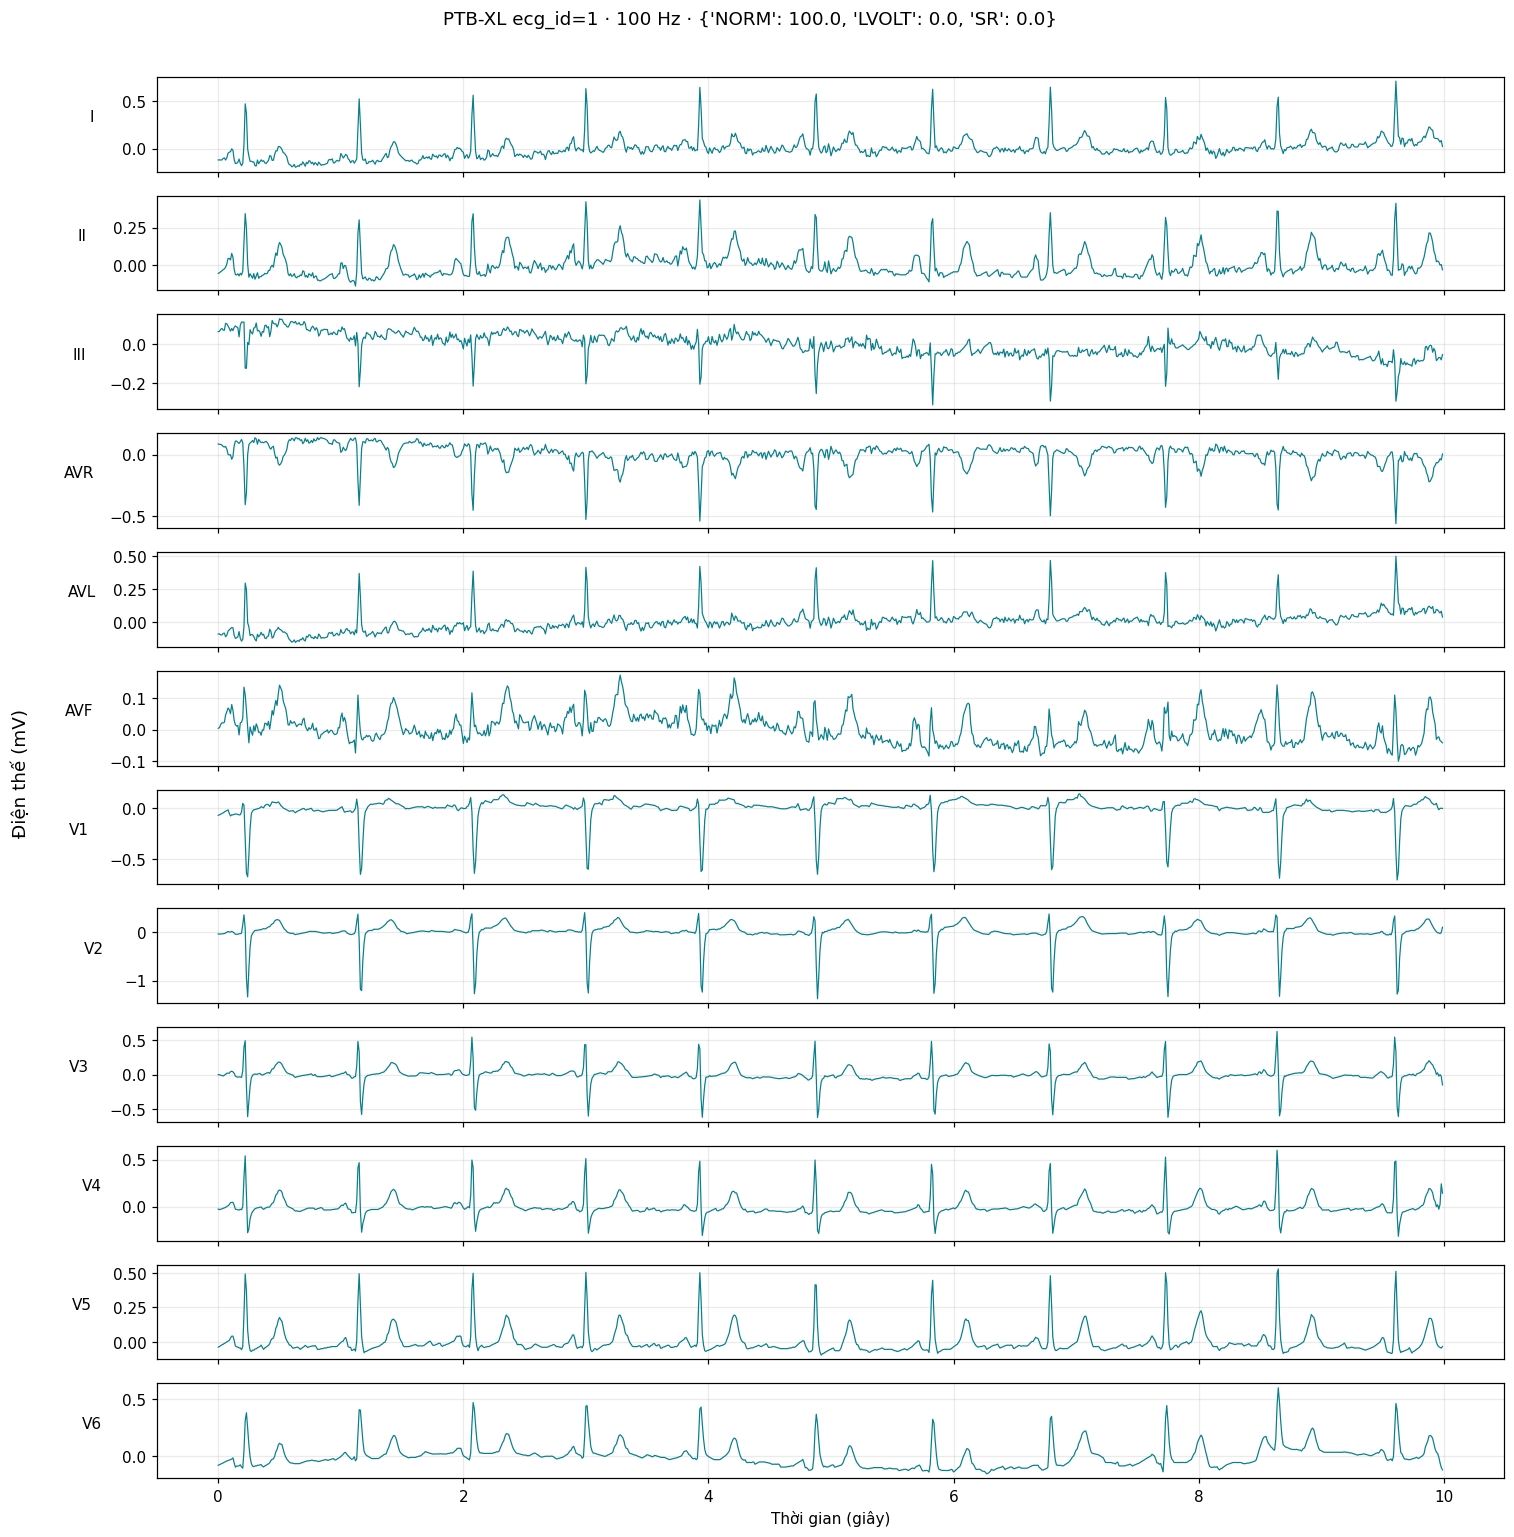

In [6]:
RECORD_ID = 1       # 1 có mã NORM; 351 có mã AFIB
SAMPLE_RATE = 100  # đổi thành 500 để xem bản phân giải cao

t, signal, leads = load_ptbxl(RECORD_ID, SAMPLE_RATE)
fig, axes = plt.subplots(12, 1, figsize=(14, 14), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t, signal[:, i], lw=0.8, color="#087f8c")
    ax.set_ylabel(leads[i], rotation=0, labelpad=20)
axes[-1].set_xlabel("Thời gian (giây)")
fig.supylabel("Điện thế (mV)")
labels = meta.loc[meta.ecg_id == RECORD_ID, "codes"].iloc[0]
fig.suptitle(f"PTB-XL ecg_id={RECORD_ID} · {SAMPLE_RATE} Hz · {labels}", y=0.995)
fig.tight_layout(rect=(0.02, 0, 1, 0.985))
plt.show()


## 6. So sánh riêng lead II: hai bản ghi khác nhãn

Đây là hình minh họa tín hiệu một kênh. Chỉ nhìn hai hình không đủ kết luận chẩn đoán. Lead II của PTB-XL cũng **không đồng nhất** với vị trí điện cực dây ngực Polar H10.

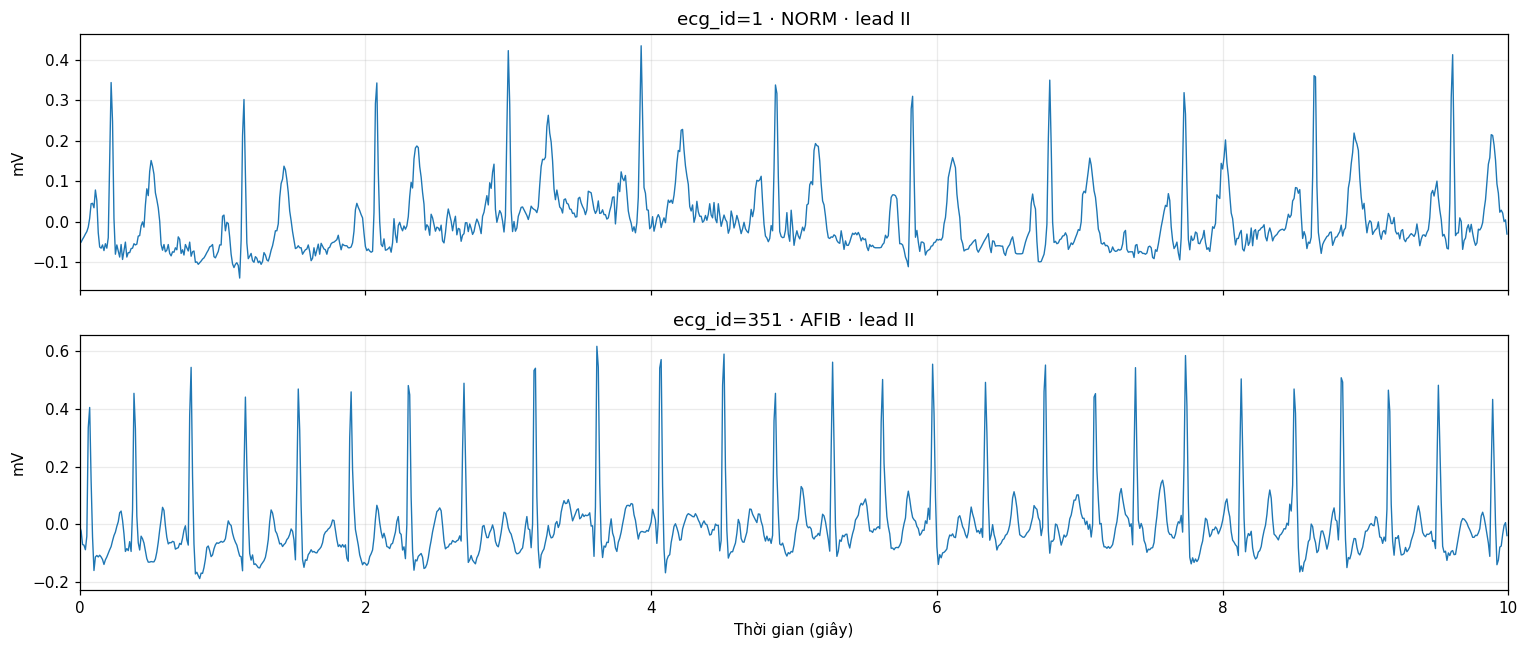

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, (record_id, label) in zip(axes, [(1, "NORM"), (351, "AFIB")]):
    t, x, leads = load_ptbxl(record_id, 100)
    ax.plot(t, x[:, leads.index("II")], lw=0.9)
    ax.set(title=f"ecg_id={record_id} · {label} · lead II",
           ylabel="mV", xlim=(0, 10))
axes[-1].set_xlabel("Thời gian (giây)")
fig.tight_layout()
plt.show()


## 7. So sánh cùng bản ghi ở 100 và 500 Hz

Hai file cùng ecg_id và cùng nhãn. Bản 100 Hz là bản được giảm tần số lấy mẫu. Không đưa hai phiên bản của một bản ghi vào hai tập train/test khác nhau.

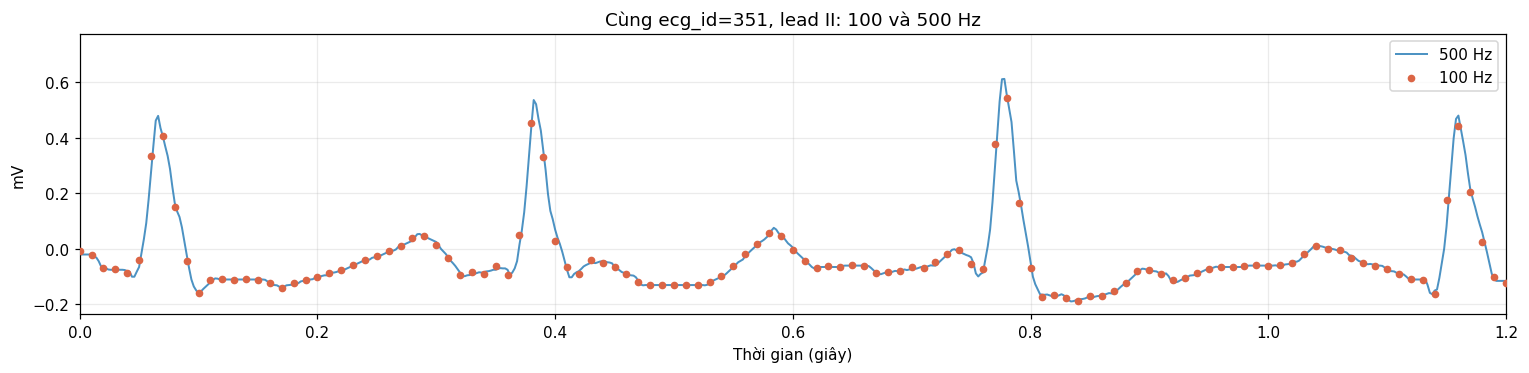

In [8]:
record_id, lead = 351, "II"
t100, x100, leads100 = load_ptbxl(record_id, 100)
t500, x500, leads500 = load_ptbxl(record_id, 500)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(t500, x500[:, leads500.index(lead)], label="500 Hz", lw=1.3, alpha=0.8)
ax.scatter(t100, x100[:, leads100.index(lead)], label="100 Hz",
           s=16, color="#db6545", zorder=3)
ax.set(xlim=(0, 1.2), xlabel="Thời gian (giây)", ylabel="mV",
       title=f"Cùng ecg_id={record_id}, lead {lead}: 100 và 500 Hz")
ax.legend()
fig.tight_layout()
plt.show()


## 8. Liên hệ với Polar H10

- PTB-XL là ECG **12 chuyển đạo**, 10 giây/bản ghi; Polar H10 gửi **một luồng ECG dây ngực ở 130 Hz**. Chọn một lead PTB-XL để thử nghiệm không khiến nó tương đương ECG H10.
- Nếu thử AI về AFIB, xử lý nhãn đa mã và các bản ghi AFIB/NORM chồng lấp; giữ chia fold theo người (1–8 train, 9 validation, 10 test).
- Sau khi train trên PTB-XL, cần kiểm tra riêng bằng ECG H10 có nhãn đáng tin cậy. Metric PTB-XL không phải hiệu năng trên H10.
- PTB-XL không có ACC hay nhãn té ngã đồng bộ, nên không dùng trực tiếp cho model té ngã hiện tại.

Notebook chỉ giúp khám phá dataset, chưa xây dựng model hay nối ECG vào app.